# Notebook 07 — Thí nghiệm với Transformer

## Mục tiêu

Nghiên cứu cách các siêu tham số khác nhau ảnh hưởng đến hiệu suất của mô hình Transformer.

Các thí nghiệm:

1. Kích thước biểu diễn của mô hình (Model Dimension)
2. Số lượng tầng Transformer (Number of Layers)
3. Số lượng đầu Attention (Number of Attention Heads)
4. Thời gian huấn luyện (Training Duration)
5. Tốc độ học (Learning Rate)

## Phương pháp nghiên cứu

Dự đoán → Thực nghiệm có kiểm soát → Quan sát → Phân tích → Kết luận

## Các chỉ số đánh giá

- Training Loss: Mức độ sai lệch trên dữ liệu huấn luyện.
- Validation Loss: Mức độ sai lệch trên dữ liệu kiểm định.
- Training Time: Thời gian huấn luyện mô hình.
- Number of Parameters: Tổng số tham số của mô hình.

In [4]:
import math
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import urllib.request

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Device:", device)

PyTorch version: 2.14.1+cpu
Device: cpu


## 1. Chuẩn bị dữ liệu

**Bộ dữ liệu:** Tiny Shakespeare

Bộ dữ liệu chứa các văn bản được biểu diễn ở cấp độ ký tự (Character-level).

Từ vựng và cách chia dữ liệu sẽ được giữ cố định trong tất cả các thí nghiệm nhằm đảm bảo tính công bằng khi so sánh kết quả.

- Tỷ lệ dữ liệu huấn luyện (Training ratio): 90%
- Tỷ lệ dữ liệu kiểm định (Validation ratio): 10%
- Độ dài chuỗi đầu vào (Block size): 64
- Kích thước mỗi batch (Batch size): 32

In [5]:
url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"

with urllib.request.urlopen(url) as response:
    text = response.read().decode("utf-8")

vocab = sorted(list(set(text)))
vocab_size = len(vocab)

char_to_id = {char: i for i, char in enumerate(vocab)}
id_to_char = {i: char for i, char in enumerate(vocab)}

data = torch.tensor(
    [char_to_id[char] for char in text],
    dtype=torch.long
)

train_size = int(0.9 * len(data))
train_data = data[:train_size]
val_data = data[train_size:]

block_size = 64
batch_size = 32

def get_batch(split):
    source = train_data if split == "train" else val_data
    indices = torch.randint(len(source) - block_size - 1, (batch_size,))

    x = torch.stack([source[i:i + block_size] for i in indices])
    y = torch.stack([source[i + 1:i + block_size + 1] for i in indices])

    return x.to(device), y.to(device)

print("Dataset size:", len(data))
print("Vocabulary size:", vocab_size)
print("Training samples:", len(train_data))
print("Validation samples:", len(val_data))
print("Batch shape:", get_batch("train")[0].shape)

Dataset size: 1115394
Vocabulary size: 65
Training samples: 1003854
Validation samples: 111540
Batch shape: torch.Size([32, 64])


## 2. Kiến trúc mô hình

Kiến trúc Transformer sẽ được giữ nhất quán trong các thí nghiệm.

**Cấu hình cơ sở (Baseline Configuration):**

- Kích thước từ vựng (Vocabulary size): 65
- Kích thước biểu diễn của mô hình (Model dimension): 64
- Số lượng đầu Attention (Attention heads): 4
- Kích thước mạng Feed-Forward (Feed-forward dimension): 256
- Số lượng tầng Transformer (Transformer layers): 2
- Độ dài chuỗi đầu vào (Block size): 64

Trong mỗi thí nghiệm, chỉ thay đổi siêu tham số đang được nghiên cứu, các thông số còn lại được giữ cố định để đảm bảo kết quả so sánh có ý nghĩa.

In [6]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2) *
            (-math.log(10000.0) / d_model)
        )
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1), :]

In [7]:
class CausalMultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads):
        super().__init__()
        assert d_model % num_heads == 0

        self.num_heads = num_heads
        self.head_dim = d_model // num_heads

        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)

    def forward(self, x):
        B, T, C = x.shape

        Q = self.W_q(x)
        K = self.W_k(x)
        V = self.W_v(x)

        Q = Q.view(B, T, self.num_heads, self.head_dim).transpose(1, 2)
        K = K.view(B, T, self.num_heads, self.head_dim).transpose(1, 2)
        V = V.view(B, T, self.num_heads, self.head_dim).transpose(1, 2)

        scores = Q @ K.transpose(-2, -1)
        scores = scores / math.sqrt(self.head_dim)

        mask = torch.tril(torch.ones(T, T, device=x.device))
        scores = scores.masked_fill(mask == 0, float("-inf"))

        weights = F.softmax(scores, dim=-1)

        output = weights @ V
        output = output.transpose(1, 2).contiguous().view(B, T, C)
        output = self.W_o(output)

        return output, weights

In [8]:
class FeedForwardNetwork(nn.Module):
    def __init__(self, d_model, d_ff):
        super().__init__()
        self.linear1 = nn.Linear(d_model, d_ff)
        self.relu = nn.ReLU()
        self.linear2 = nn.Linear(d_ff, d_model)

    def forward(self, x):
        return self.linear2(self.relu(self.linear1(x)))


class CausalTransformerBlock(nn.Module):
    def __init__(self, d_model, num_heads, d_ff):
        super().__init__()
        self.attention = CausalMultiHeadAttention(d_model, num_heads)
        self.norm1 = nn.LayerNorm(d_model)
        self.ffn = FeedForwardNetwork(d_model, d_ff)
        self.norm2 = nn.LayerNorm(d_model)

    def forward(self, x):
        attention_output, weights = self.attention(x)
        x = self.norm1(x + attention_output)

        ffn_output = self.ffn(x)
        output = self.norm2(x + ffn_output)

        return output, weights

In [9]:
class TransformerLanguageModel(nn.Module):
    def __init__(self, vocab_size, d_model, num_heads, d_ff, num_layers, max_len):
        super().__init__()

        self.embedding = nn.Embedding(vocab_size, d_model)
        self.positional_encoding = PositionalEncoding(d_model, max_len)

        self.blocks = nn.ModuleList([
            CausalTransformerBlock(d_model, num_heads, d_ff)
            for _ in range(num_layers)
        ])

        self.output_layer = nn.Linear(d_model, vocab_size)

    def forward(self, token_ids):
        x = self.embedding(token_ids)
        x = self.positional_encoding(x)

        for block in self.blocks:
            x, _ = block(x)

        logits = self.output_layer(x)

        return logits

In [10]:
baseline_config = {
    "d_model": 64,
    "num_heads": 4,
    "d_ff": 256,
    "num_layers": 2
}

torch.manual_seed(42)

model = TransformerLanguageModel(
    vocab_size=vocab_size,
    d_model=baseline_config["d_model"],
    num_heads=baseline_config["num_heads"],
    d_ff=baseline_config["d_ff"],
    num_layers=baseline_config["num_layers"],
    max_len=block_size
).to(device)

x, y = get_batch("train")
logits = model(x)

total_params = sum(p.numel() for p in model.parameters())

print("Input shape:", x.shape)
print("Output shape:", logits.shape)
print("Total parameters:", total_params)
print("Baseline configuration:", baseline_config)

Input shape: torch.Size([32, 64])
Output shape: torch.Size([32, 64, 65])
Total parameters: 108353
Baseline configuration: {'d_model': 64, 'num_heads': 4, 'd_ff': 256, 'num_layers': 2}


## 3. Thí nghiệm 1 — Thời gian huấn luyện

### Câu hỏi nghiên cứu

Thời gian huấn luyện ảnh hưởng như thế nào đến hiệu suất của mô hình Transformer?

### Giả thuyết

Khi tăng số lần lặp huấn luyện (Training Iterations), Training Loss và Validation Loss ban đầu sẽ giảm.

Tuy nhiên, nếu huấn luyện quá lâu, mô hình có thể gặp hiện tượng quá khớp (Overfitting).

### Biến độc lập

- Số lần lặp huấn luyện (Number of Training Iterations).

### Các biến được kiểm soát

- Kiến trúc mô hình (Model Architecture).
- Tốc độ học (Learning Rate).
- Kích thước batch (Batch Size).
- Bộ dữ liệu (Dataset).

In [11]:
torch.manual_seed(42)

model = TransformerLanguageModel(
    vocab_size=vocab_size,
    d_model=64,
    num_heads=4,
    d_ff=256,
    num_layers=2,
    max_len=block_size
).to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=0.001)

checkpoints = [100, 250, 500]
results = []

max_iters = max(checkpoints)

print("Training checkpoints:", checkpoints)
print("Maximum iterations:", max_iters)

Training checkpoints: [100, 250, 500]
Maximum iterations: 500


In [12]:
def evaluate_model(model, split, eval_iters=30):
    model.eval()
    losses = []

    with torch.no_grad():
        for _ in range(eval_iters):
            x, y = get_batch(split)
            logits = model(x)
            loss = F.cross_entropy(
                logits.reshape(-1, vocab_size),
                y.reshape(-1)
            )
            losses.append(loss.item())

    model.train()
    return np.mean(losses)


start_time = time.time()

for iteration in range(1, max_iters + 1):
    model.train()

    x, y = get_batch("train")
    logits = model(x)

    loss = F.cross_entropy(
        logits.reshape(-1, vocab_size),
        y.reshape(-1)
    )

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

    if iteration in checkpoints:
        train_loss = evaluate_model(model, "train")
        val_loss = evaluate_model(model, "val")
        elapsed = time.time() - start_time

        results.append({
            "iterations": iteration,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "time": elapsed
        })

        print(
            f"Iteration: {iteration} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Time: {elapsed:.2f}s"
        )

Iteration: 500 | Train Loss: 2.1495 | Val Loss: 2.1976 | Time: 11.30s


## Quan sát

- Tại 250 iterations:
  - Train Loss: 2.3351
  - Validation Loss: 2.3383

- Tại 500 iterations:
  - Train Loss: 2.1495
  - Validation Loss: 2.1976

Cả Training Loss và Validation Loss đều giảm khi thời gian huấn luyện tăng lên.

Mô hình cho thấy hiệu suất được cải thiện và chưa xuất hiện dấu hiệu quá khớp rõ rệt.

## Kết luận sơ bộ

Việc tăng số lần lặp huấn luyện từ 250 lên 500 đã giúp cải thiện khả năng mô hình hóa ngôn ngữ.

Cần thực hiện thêm các thí nghiệm với thời gian huấn luyện dài hơn để xác định liệu sự cải thiện này có tiếp tục hay không.

## 4. Trực quan hóa kết quả thí nghiệm 1

Sử dụng biểu đồ đường để so sánh Training Loss và Validation Loss tại các mốc huấn luyện.

Mục đích:
- Quan sát xu hướng thay đổi của Loss.
- So sánh hiệu suất giữa các mốc huấn luyện.
- Đánh giá sơ bộ khả năng xuất hiện Overfitting.

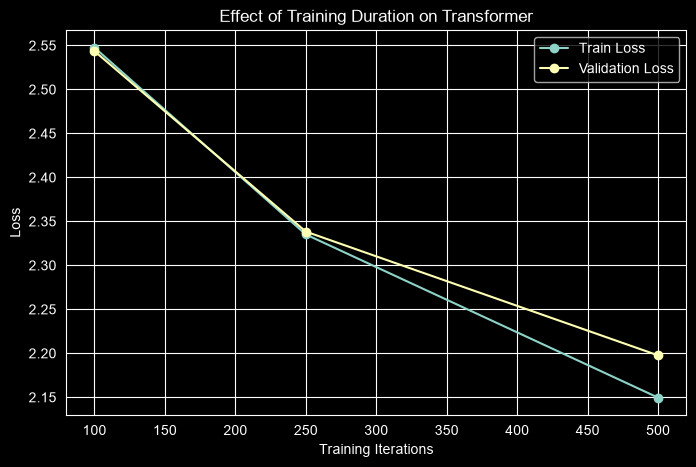

In [13]:
iterations = [item["iterations"] for item in results]
train_losses = [item["train_loss"] for item in results]
val_losses = [item["val_loss"] for item in results]

plt.figure(figsize=(8, 5))

plt.plot(iterations, train_losses, marker="o", label="Train Loss")
plt.plot(iterations, val_losses, marker="o", label="Validation Loss")

plt.xlabel("Training Iterations")
plt.ylabel("Loss")
plt.title("Effect of Training Duration on Transformer")
plt.legend()
plt.grid(True)
plt.show()

## 5. Thí nghiệm 2 — Kích thước biểu diễn của mô hình

### Câu hỏi nghiên cứu

Kích thước biểu diễn của mô hình (Model Dimension) ảnh hưởng như thế nào đến hiệu suất của Transformer?

### Giả thuyết

Khi tăng Model Dimension, mô hình có nhiều khả năng biểu diễn thông tin hơn.

Tuy nhiên, số lượng tham số và chi phí tính toán cũng tăng lên. Vì vậy, Model Dimension lớn hơn không nhất thiết luôn mang lại kết quả tốt hơn.

### Biến độc lập

- Model Dimension: 32, 64, 128.

### Các biến được kiểm soát

- Số lượng Attention Heads: 4.
- Số lượng Transformer Layers: 2.
- Feed-forward Dimension: 4 × Model Dimension.
- Learning Rate: 0.001.
- Batch Size: 32.
- Block Size: 64.
- Training Iterations: 200.

In [14]:
d_model_values = [32, 64, 128]
experiment_results = []

training_iterations = 200

print("Model Dimensions:", d_model_values)
print("Training Iterations:", training_iterations)

Model Dimensions: [32, 64, 128]
Training Iterations: 200


In [15]:
def run_experiment(d_model, num_heads=4, num_layers=2, iterations=200):
    d_ff = d_model * 4

    torch.manual_seed(42)

    model = TransformerLanguageModel(
        vocab_size=vocab_size,
        d_model=d_model,
        num_heads=num_heads,
        d_ff=d_ff,
        num_layers=num_layers,
        max_len=block_size
    ).to(device)

    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001)

    total_params = sum(p.numel() for p in model.parameters())
    start_time = time.time()

    for _ in range(iterations):
        model.train()

        x, y = get_batch("train")
        logits = model(x)

        loss = F.cross_entropy(
            logits.reshape(-1, vocab_size),
            y.reshape(-1)
        )

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

    train_loss = evaluate_model(model, "train")
    val_loss = evaluate_model(model, "val")
    elapsed = time.time() - start_time

    return {
        "d_model": d_model,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "parameters": total_params,
        "time": elapsed
    }

In [16]:
for d_model in d_model_values:
    result = run_experiment(d_model)
    experiment_results.append(result)

    print(
        f"d_model: {result['d_model']} | "
        f"Train Loss: {result['train_loss']:.4f} | "
        f"Val Loss: {result['val_loss']:.4f} | "
        f"Parameters: {result['parameters']:,} | "
        f"Time: {result['time']:.2f}s"
    )

d_model: 128 | Train Loss: 2.2167 | Val Loss: 2.2462 | Parameters: 413,249 | Time: 8.32s


In [17]:
print("Configured dimensions:", d_model_values)
print("Completed experiments:", len(experiment_results))

for result in experiment_results:
    print(result)

Configured dimensions: [32, 64, 128]
Completed experiments: 3
{'d_model': 32, 'train_loss': np.float64(2.572930081685384), 'val_loss': np.float64(2.566608691215515), 'parameters': 29633, 'time': 3.6691858768463135}
{'d_model': 64, 'train_loss': np.float64(2.392744779586792), 'val_loss': np.float64(2.4056063095728555), 'parameters': 108353, 'time': 3.81841778755188}
{'d_model': 128, 'train_loss': np.float64(2.2166848182678223), 'val_loss': np.float64(2.246187774340312), 'parameters': 413249, 'time': 8.315770626068115}


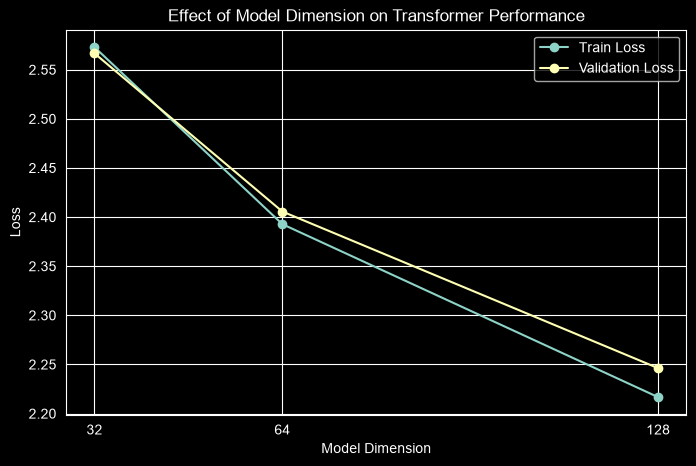

In [18]:
dimensions = [r["d_model"] for r in experiment_results]
train_losses = [r["train_loss"] for r in experiment_results]
val_losses = [r["val_loss"] for r in experiment_results]

plt.figure(figsize=(8, 5))

plt.plot(dimensions, train_losses, marker="o", label="Train Loss")
plt.plot(dimensions, val_losses, marker="o", label="Validation Loss")

plt.xlabel("Model Dimension")
plt.ylabel("Loss")
plt.title("Effect of Model Dimension on Transformer Performance")
plt.xticks(dimensions)
plt.legend()
plt.grid(True)
plt.show()

## Quan sát

- Khi Model Dimension tăng từ 32 lên 128, cả Training Loss và Validation Loss đều giảm.
- Cấu hình d_model = 128 đạt Validation Loss thấp nhất (2.2462).
- Số lượng tham số tăng từ 29,633 lên 413,249.
- Thời gian huấn luyện tăng từ 3.67 giây lên 8.32 giây.

## Kết luận sơ bộ

Trong thí nghiệm này, tăng Model Dimension giúp cải thiện khả năng học của Transformer.

Tuy nhiên, mô hình lớn hơn cũng yêu cầu nhiều tham số và thời gian tính toán hơn.

Do đó, việc lựa chọn Model Dimension cần cân bằng giữa hiệu suất và chi phí tính toán.

Lưu ý: Kết quả mới dựa trên một lần chạy cho mỗi cấu hình và 200 iterations. Cần thêm lần chạy để đánh giá độ ổn định.

## 6. Thí nghiệm 3 — Số lượng tầng Transformer

### Câu hỏi nghiên cứu

Số lượng tầng Transformer (Number of Layers) ảnh hưởng như thế nào đến hiệu suất của mô hình?

### Giả thuyết

Tăng số lượng tầng Transformer có thể giúp mô hình học được các biểu diễn thông tin phức tạp hơn.

Tuy nhiên, số lượng tham số và chi phí tính toán cũng tăng theo. Vì vậy, nhiều tầng hơn không nhất thiết luôn mang lại hiệu suất tốt hơn.

### Biến độc lập

- Number of Layers: 1, 2, 3.

### Các biến được kiểm soát

- Model Dimension: 64.
- Attention Heads: 4.
- Feed-forward Dimension: 256.
- Learning Rate: 0.001.
- Batch Size: 32.
- Block Size: 64.
- Training Iterations: 200.

In [19]:
layer_values = [1, 2, 3]
layer_results = []

training_iterations = 200

print("Transformer Layers:", layer_values)
print("Training Iterations:", training_iterations)

Transformer Layers: [1, 2, 3]
Training Iterations: 200


In [20]:
for num_layers in layer_values:
    result = run_experiment(
        d_model=64,
        num_layers=num_layers,
        iterations=training_iterations
    )

    layer_results.append({
        "num_layers": num_layers,
        "train_loss": result["train_loss"],
        "val_loss": result["val_loss"],
        "parameters": result["parameters"],
        "time": result["time"]
    })

    print(
        f"Layers: {num_layers} | "
        f"Train Loss: {result['train_loss']:.4f} | "
        f"Val Loss: {result['val_loss']:.4f} | "
        f"Parameters: {result['parameters']:,} | "
        f"Time: {result['time']:.2f}s"
    )

Layers: 3 | Train Loss: 2.3760 | Val Loss: 2.3750 | Parameters: 158,337 | Time: 7.79s


In [21]:
print("Configured layers:", layer_values)
print("Completed experiments:", len(layer_results))

for result in layer_results:
    print(result)

Configured layers: [1, 2, 3]
Completed experiments: 3
{'num_layers': 1, 'train_loss': np.float64(2.443808356920878), 'val_loss': np.float64(2.440530300140381), 'parameters': 58369, 'time': 3.169363021850586}
{'num_layers': 2, 'train_loss': np.float64(2.392744779586792), 'val_loss': np.float64(2.4056063095728555), 'parameters': 108353, 'time': 4.3225014209747314}
{'num_layers': 3, 'train_loss': np.float64(2.3759520371754963), 'val_loss': np.float64(2.3750090837478637), 'parameters': 158337, 'time': 7.788444757461548}


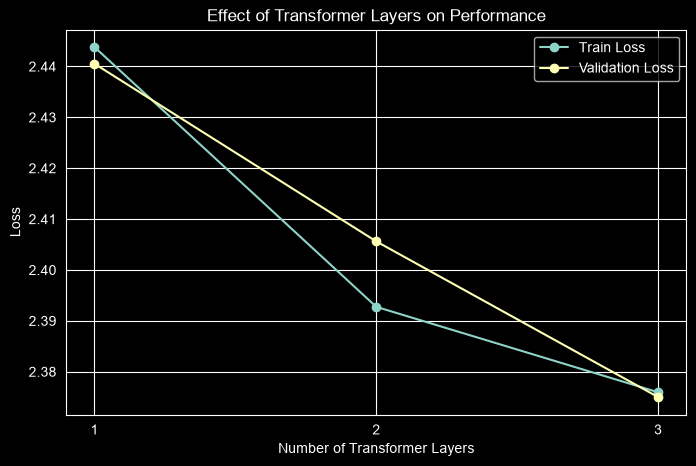

In [22]:
layers = [r["num_layers"] for r in layer_results]
train_losses = [r["train_loss"] for r in layer_results]
val_losses = [r["val_loss"] for r in layer_results]

plt.figure(figsize=(8, 5))

plt.plot(layers, train_losses, marker="o", label="Train Loss")
plt.plot(layers, val_losses, marker="o", label="Validation Loss")

plt.xlabel("Number of Transformer Layers")
plt.ylabel("Loss")
plt.title("Effect of Transformer Layers on Performance")
plt.xticks(layers)
plt.legend()
plt.grid(True)
plt.show()

## Quan sát

- Khi số lượng Layers tăng từ 1 lên 3, Training Loss và Validation Loss đều giảm.
- Cấu hình 3 Layers đạt Validation Loss thấp nhất (2.3750).
- Số lượng tham số tăng từ 58,369 lên 158,337.
- Thời gian huấn luyện tăng từ 3.17 giây lên 7.79 giây.

## Kết luận sơ bộ

Trong thí nghiệm này, tăng số lượng Transformer Layers giúp cải thiện hiệu suất mô hình.

Tuy nhiên, việc tăng số tầng cũng làm tăng số lượng tham số và thời gian tính toán.

Do đó, cần cân nhắc giữa khả năng biểu diễn của mô hình và chi phí huấn luyện.

Lưu ý: Kết quả chỉ dựa trên một lần chạy cho mỗi cấu hình với 200 iterations.

## 7. Thí nghiệm 4 — Số lượng đầu Attention

### Câu hỏi nghiên cứu

Số lượng đầu Attention (Number of Attention Heads) ảnh hưởng như thế nào đến hiệu suất của mô hình Transformer?

### Giả thuyết

Tăng số lượng Attention Heads cho phép mô hình xử lý thông tin thông qua nhiều không gian biểu diễn khác nhau.

Tuy nhiên, khi tổng Model Dimension được giữ cố định, số lượng Heads tăng sẽ làm giảm kích thước biểu diễn của mỗi Head.

Do đó, nhiều Attention Heads hơn không nhất thiết luôn mang lại hiệu suất tốt hơn.

### Biến độc lập

- Number of Attention Heads: 1, 2, 4, 8.

### Các biến được kiểm soát

- Model Dimension: 64.
- Transformer Layers: 2.
- Feed-forward Dimension: 256.
- Learning Rate: 0.001.
- Batch Size: 32.
- Block Size: 64.
- Training Iterations: 200.

In [23]:
head_values = [1, 2, 4, 8]
head_results = []

training_iterations = 200

print("Attention Heads:", head_values)
print("Training Iterations:", training_iterations)
print("Model Dimension: 64")
print("Head Dimensions:", [64 // h for h in head_values])

Attention Heads: [1, 2, 4, 8]
Training Iterations: 200
Model Dimension: 64
Head Dimensions: [64, 32, 16, 8]


In [24]:
for num_heads in head_values:
    result = run_experiment(
        d_model=64,
        num_heads=num_heads,
        num_layers=2,
        iterations=training_iterations
    )

    head_results.append({
        "num_heads": num_heads,
        "head_dim": 64 // num_heads,
        "train_loss": result["train_loss"],
        "val_loss": result["val_loss"],
        "parameters": result["parameters"],
        "time": result["time"]
    })

    print(
        f"Heads: {num_heads} | "
        f"Head Dim: {64 // num_heads} | "
        f"Train Loss: {result['train_loss']:.4f} | "
        f"Val Loss: {result['val_loss']:.4f} | "
        f"Parameters: {result['parameters']:,} | "
        f"Time: {result['time']:.2f}s"
    )

Heads: 8 | Head Dim: 8 | Train Loss: 2.4057 | Val Loss: 2.4180 | Parameters: 108,353 | Time: 9.04s


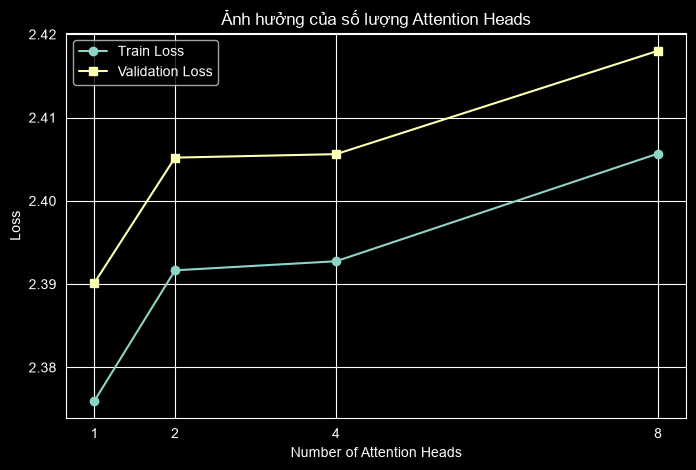

In [25]:
heads = [result["num_heads"] for result in head_results]
train_losses = [result["train_loss"] for result in head_results]
val_losses = [result["val_loss"] for result in head_results]

plt.figure(figsize=(8, 5))
plt.plot(heads, train_losses, marker="o", label="Train Loss")
plt.plot(heads, val_losses, marker="s", label="Validation Loss")

plt.xlabel("Number of Attention Heads")
plt.ylabel("Loss")
plt.title("Ảnh hưởng của số lượng Attention Heads")
plt.xticks(heads)
plt.legend()
plt.grid(True)
plt.show()

### Nhận xét (Observation)

- Khi tăng số lượng Attention Heads từ 1 lên 8, Train Loss và Validation Loss có xu hướng tăng.
- Cấu hình 1 Head đạt Loss thấp nhất trong lần thử nghiệm.
- Cấu hình 8 Heads có Loss cao nhất và thời gian huấn luyện dài nhất.
- Số lượng Parameters không thay đổi giữa các cấu hình (108,353).
- Việc tăng số Attention Heads không đảm bảo cải thiện hiệu suất mô hình.

### Kết luận (Conclusion)

Số lượng Attention Heads ảnh hưởng đến cách Transformer phân chia và xử lý thông tin trong không gian biểu diễn.

Với Model Dimension cố định bằng 64, tăng số Heads làm giảm Head Dimension. Trong thí nghiệm này, cấu hình 1 Head cho kết quả tốt nhất.

Tuy nhiên, không thể kết luận rằng ít Attention Heads luôn tốt hơn. Hiệu suất còn phụ thuộc vào dữ liệu, kiến trúc và quá trình huấn luyện.

## 8. Thí nghiệm 5 — Tốc độ học (Learning Rate)

### Câu hỏi nghiên cứu

Learning Rate ảnh hưởng như thế nào đến tốc độ hội tụ và hiệu suất của mô hình Transformer?

### Giả thuyết

- Learning Rate quá nhỏ có thể khiến mô hình học chậm.
- Learning Rate quá lớn có thể khiến quá trình huấn luyện không ổn định.
- Một Learning Rate phù hợp có thể giúp mô hình hội tụ tốt hơn.

### Biến độc lập

- Learning Rate: 0.0001, 0.001, 0.01.

### Các biến được kiểm soát

- Model Dimension: 64.
- Attention Heads: 4.
- Transformer Layers: 2.
- Feed-forward Dimension: 256.
- Batch Size: 32.
- Block Size: 64.
- Training Iterations: 200.

In [26]:
def run_experiment(
        d_model,
        num_heads=4,
        num_layers=2,
        iterations=200,
        learning_rate=0.001
):
    d_ff = d_model * 4

    torch.manual_seed(42)

    model = TransformerLanguageModel(
        vocab_size,
        d_model,
        num_heads,
        d_ff,
        num_layers,
        block_size
    ).to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate
    )

    total_params = sum(p.numel() for p in model.parameters())
    start_time = time.time()

    for _ in range(iterations):
        model.train()
        x, y = get_batch("train")
        logits = model(x)

        loss = F.cross_entropy(
            logits.reshape(-1, vocab_size),
            y.reshape(-1)
        )

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

    train_loss = evaluate_model(model, "train")
    val_loss = evaluate_model(model, "val")
    elapsed = time.time() - start_time

    return {
        "d_model": d_model,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "parameters": total_params,
        "time": elapsed,
        "learning_rate": learning_rate
    }

In [27]:
learning_rates = [0.0001, 0.001, 0.01]
lr_results = []
training_iterations = 200

for lr in learning_rates:
    result = run_experiment(
        d_model=64,
        num_heads=4,
        num_layers=2,
        iterations=training_iterations,
        learning_rate=lr
    )

    lr_results.append(result)

    print(
        f"Learning Rate: {lr} | "
        f"Train Loss: {result['train_loss']:.4f} | "
        f"Val Loss: {result['val_loss']:.4f} | "
        f"Parameters: {result['parameters']:,} | "
        f"Time: {result['time']:.2f}s"
    )

Learning Rate: 0.01 | Train Loss: 2.1431 | Val Loss: 2.2123 | Parameters: 108,353 | Time: 6.43s


In [28]:
for result in lr_results:
    print(result)

{'d_model': 64, 'train_loss': np.float64(3.0992421468098956), 'val_loss': np.float64(3.118364357948303), 'parameters': 108353, 'time': 8.47451901435852, 'learning_rate': 0.0001}
{'d_model': 64, 'train_loss': np.float64(2.392744779586792), 'val_loss': np.float64(2.4056063095728555), 'parameters': 108353, 'time': 6.633471727371216, 'learning_rate': 0.001}
{'d_model': 64, 'train_loss': np.float64(2.143072724342346), 'val_loss': np.float64(2.212305847803752), 'parameters': 108353, 'time': 6.426029920578003, 'learning_rate': 0.01}


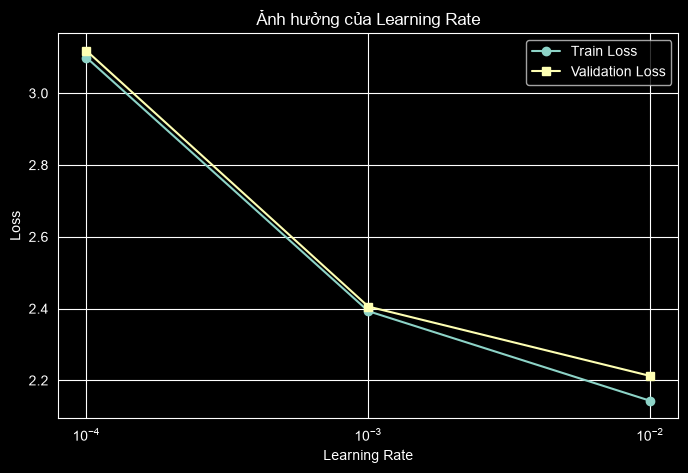

In [29]:
learning_rates = [result["learning_rate"] for result in lr_results]
train_losses = [result["train_loss"] for result in lr_results]
val_losses = [result["val_loss"] for result in lr_results]

plt.figure(figsize=(8, 5))
plt.plot(learning_rates, train_losses, marker="o", label="Train Loss")
plt.plot(learning_rates, val_losses, marker="s", label="Validation Loss")

plt.xscale("log")
plt.xlabel("Learning Rate")
plt.ylabel("Loss")
plt.title("Ảnh hưởng của Learning Rate")
plt.legend()
plt.grid(True)
plt.show()

### Nhận xét (Observation)

- Learning Rate = 0.0001 cho Train Loss và Validation Loss cao nhất.
- Khi tăng Learning Rate lên 0.001, cả hai loại Loss đều giảm đáng kể.
- Learning Rate = 0.01 đạt kết quả tốt nhất với Train Loss = 2.1431 và Validation Loss = 2.2123.
- Khoảng cách giữa Train Loss và Validation Loss tương đối nhỏ ở cả ba cấu hình.
- Số lượng Parameters không thay đổi (108,353).

### Kết luận (Conclusion)

Learning Rate ảnh hưởng trực tiếp đến tốc độ cập nhật trọng số và khả năng hội tụ của mô hình.

Learning Rate quá nhỏ có thể khiến mô hình học chậm trong một số lượng Iterations giới hạn.

Trong thí nghiệm này, Learning Rate = 0.01 cho kết quả tốt nhất sau 200 Iterations.

Tuy nhiên, Learning Rate quá lớn vẫn có thể khiến quá trình huấn luyện không ổn định. Vì vậy, cần thử nghiệm thêm nhiều giá trị và theo dõi Loss qua từng giai đoạn để xác định mức phù hợp.

# 9. Tổng kết thí nghiệm

## Mục tiêu

Khảo sát ảnh hưởng của các siêu tham số (Hyperparameters) đến hiệu suất của mô hình Transformer trên tập dữ liệu Tiny Shakespeare.

## Tổng hợp kết quả

| Thí nghiệm | Kết quả quan sát |
|---|---|
| Training Duration | Loss giảm khi tăng số Iterations |
| Model Dimension | Dimension lớn hơn giúp giảm Validation Loss trong phạm vi thử nghiệm |
| Number of Layers | Tăng số Layers giúp cải thiện Validation Loss |
| Number of Attention Heads | Nhiều Heads hơn không đảm bảo hiệu suất tốt hơn |
| Learning Rate | Learning Rate ảnh hưởng rõ rệt đến tốc độ hội tụ |

## Kết luận chung

Các thí nghiệm cho thấy hiệu suất của Transformer phụ thuộc vào nhiều siêu tham số khác nhau.

- Model Dimension và Number of Layers ảnh hưởng đến năng lực biểu diễn của mô hình.
- Number of Attention Heads ảnh hưởng đến cách phân chia không gian biểu diễn trong Attention.
- Training Duration và Learning Rate ảnh hưởng đến quá trình tối ưu hóa.
- Tăng kích thước mô hình có thể cải thiện kết quả nhưng cũng làm tăng số Parameters và thời gian huấn luyện.

## Hạn chế

- Mỗi cấu hình chỉ được thử nghiệm một lần.
- Một số thí nghiệm sử dụng số Iterations tương đối nhỏ.
- Các Batch được lấy ngẫu nhiên nên kết quả có thể dao động.
- Chưa thực hiện tìm kiếm siêu tham số trên phạm vi rộng.

## Hướng phát triển

- Chạy lại các thí nghiệm với nhiều Random Seeds.
- Tăng số lượng Training Iterations.
- Khảo sát thêm các giá trị Learning Rate.
- So sánh Transformer với RNN và LSTM trên cùng tập dữ liệu.
- Đánh giá khả năng sinh văn bản bằng các tiêu chí bổ sung.